Dataset Shape: (150, 4)
Actual Classes: ['setosa' 'versicolor' 'virginica']

Actual vs Predicted Clusters:
  Actual Class  Predicted Cluster
0       setosa                  1
1       setosa                  1
2       setosa                  1
3       setosa                  1
4       setosa                  1
5       setosa                  1
6       setosa                  1
7       setosa                  1
8       setosa                  1
9       setosa                  1

Cluster Comparison Table:
Predicted Cluster   0   1   2
Actual Class                 
setosa              0  50   0
versicolor         39   0  11
virginica          14   0  36

Clustering Evaluation Results
Homogeneity Score: 0.6591
Completeness Score: 0.6598
Adjusted Rand Index: 0.6201


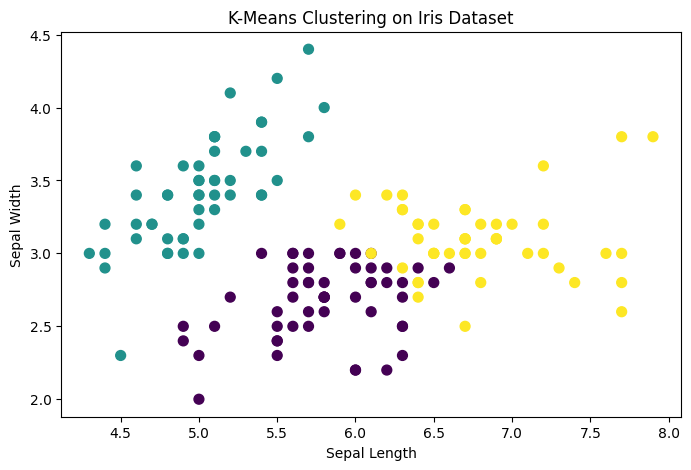

In [2]:


import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    homogeneity_score,
    completeness_score,
    adjusted_rand_score
)

iris = load_iris()

X = iris.data
y_true = iris.target

print("Dataset Shape:", X.shape)
print("Actual Classes:", iris.target_names)


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

y_pred = kmeans.fit_predict(X_scaled)


comparison = pd.DataFrame({
    "Actual Class": iris.target_names[y_true],
    "Predicted Cluster": y_pred
})

print("\nActual vs Predicted Clusters:")
print(comparison.head(10))


print("\nCluster Comparison Table:")

print(pd.crosstab(
    comparison["Actual Class"],
    comparison["Predicted Cluster"]
))


h = homogeneity_score(y_true, y_pred)


c = completeness_score(y_true, y_pred)


ari = adjusted_rand_score(y_true, y_pred)


print("\nClustering Evaluation Results")

print("Homogeneity Score:", round(h, 4))
print("Completeness Score:", round(c, 4))
print("Adjusted Rand Index:", round(ari, 4))


plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y_pred,
    cmap="viridis",
    s=50
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("K-Means Clustering on Iris Dataset")

plt.show()
